In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow sürümü:", tf.__version__)

TensorFlow sürümü: 2.21.0


In [ ]:
# Fashion-MNIST veri setini yükle
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Eğitim verisi:", x_train.shape)
print("Test verisi:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Eğitim verisi: (60000, 28, 28)
Test verisi: (10000, 28, 28)


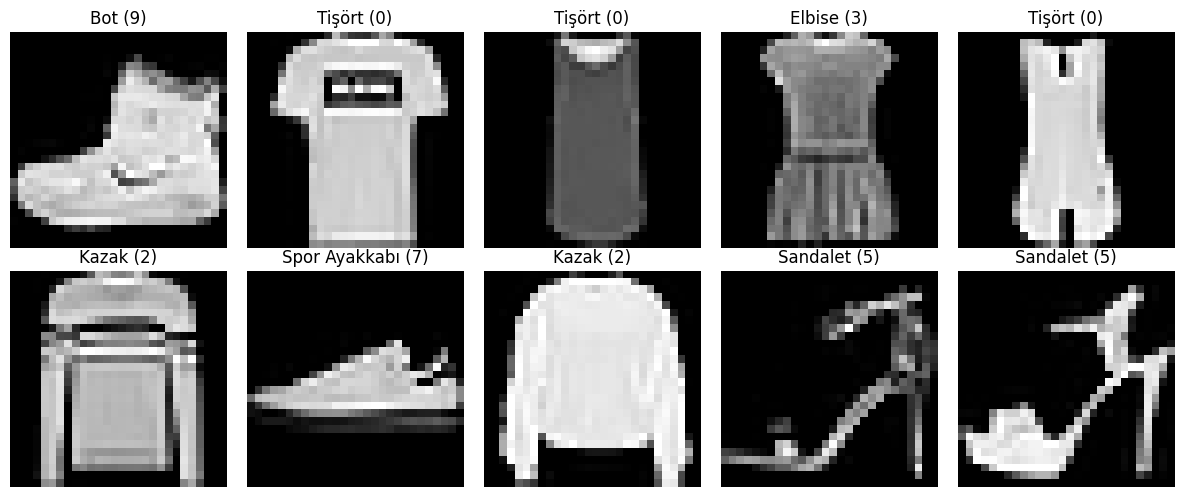

In [ ]:

# Fashion-MNIST sınıf isimleri
class_names = [
    "Tişört", "Pantolon", "Kazak", "Elbise",
    "Mont", "Sandalet", "Gömlek",
    "Spor Ayakkabı", "Çanta", "Bot"
]

# İlk 10 eğitim görüntüsünü göster
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_train[i], cmap="gray")

    plt.title(
        f"{class_names[y_train[i]]} ({y_train[i]})"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

print("İlk görüntünün boyutu:", x_train[0].shape)

print("İlk görüntünün etiketi:", y_train[0])

print("İlk görüntünün piksel değerleri:")
print(x_train[0])

print("En küçük piksel:", np.min(x_train[0]))
print("En büyük piksel:", np.max(x_train[0]))


İlk görüntünün boyutu: (28, 28)
İlk görüntünün etiketi: 9
İlk görüntünün piksel değerleri:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 12

In [ ]:

# Piksel değerlerini 0-1 aralığına getir
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Normalize edilmiş minimum:", x_train.min())
print("Normalize edilmiş maksimum:", x_train.max())


Normalize edilmiş minimum: 0.0
Normalize edilmiş maksimum: 1.0


In [ ]:

# Gri seviyeli görüntülere kanal boyutu ekle
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Eğitim verisi:", x_train.shape)
print("Test verisi:", x_test.shape)


Eğitim verisi: (60000, 28, 28, 1)
Test verisi: (10000, 28, 28, 1)


In [ ]:

# Tekrarlanabilirlik için
tf.keras.utils.set_random_seed(42)

# CNN modelini oluştur
model = tf.keras.Sequential([

    # Giriş: 28x28, tek kanallı görüntü
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # 1. Konvolüsyon: 8 adet 3x3 filtre
    tf.keras.layers.Conv2D(
        filters=8,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # 1. Max Pooling
    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # 2. Konvolüsyon: 16 adet 3x3 filtre
    tf.keras.layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # 2. Max Pooling
    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Çok boyutlu veriyi tek boyuta dönüştür
    tf.keras.layers.Flatten(),

    # 64 nöronlu Dense katmanı
    tf.keras.layers.Dense(
        units=64,
        activation="relu"
    ),

    # 10 sınıflı çıkış katmanı
    tf.keras.layers.Dense(
        units=10,
        activation="softmax"
    )
])

# Modelin katmanlarını göster
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Modelin eğitim ayarlarını belirle
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model eğitim için hazır!")


Model eğitim için hazır!


In [ ]:

import time

# Eğitim süresini ölç
start_time = time.perf_counter()

# CNN modelini eğit
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

end_time = time.perf_counter()

training_time = end_time - start_time

print("\nEğitim tamamlandı!")
print(f"Toplam eğitim süresi: {training_time:.2f} saniye")


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.7694 - loss: 0.6286 - val_accuracy: 0.8215 - val_loss: 0.4805
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.8467 - loss: 0.4236 - val_accuracy: 0.8438 - val_loss: 0.4243
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.8640 - loss: 0.3763 - val_accuracy: 0.8580 - val_loss: 0.3899
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.8744 - loss: 0.3462 - val_accuracy: 0.8645 - val_loss: 0.3610
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.8814 - loss: 0.3247 - val_accuracy: 0.8752 - val_loss: 0.3417

Eğitim tamamlandı!
Toplam eğitim süresi: 93.02 saniye


In [ ]:

# Eğitilmiş CNN modelini test et
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\n========== TEST SONUÇLARI ==========")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Doğruluğu: %{test_accuracy * 100:.2f}")
print(f"Eğitim Süresi: {training_time:.2f} saniye")


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8690 - loss: 0.3618

========== TEST SONUÇLARI ==========
Test Loss: 0.3618
Test Accuracy: 0.8690
Test Doğruluğu: %86.90
Eğitim Süresi: 93.02 saniye


In [ ]:

import tensorflow as tf
import time

# Rastgelelik kontrolü
tf.keras.utils.set_random_seed(42)

# İkinci deney: ilk Conv2D katmanı 16 filtreli
model_16 = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        16, (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        16, (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation="relu"),

    tf.keras.layers.Dense(10, activation="softmax")
])

model_16.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_16.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,794 (112.48 KB)

 Trainable params: 28,794 (112.48 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

import time

# Eğitim süresini başlat
start_time_16 = time.perf_counter()

# 16 filtreli modeli eğit
history_16 = model_16.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

# Eğitim süresini hesapla
training_time_16 = time.perf_counter() - start_time_16

print(f"Eğitim süresi: {training_time_16:.2f} saniye")


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 23s 26ms/step - accuracy: 0.7806 - loss: 0.6116 - val_accuracy: 0.8328 - val_loss: 0.4703
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.8546 - loss: 0.4031 - val_accuracy: 0.8588 - val_loss: 0.4029
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 23s 28ms/step - accuracy: 0.8715 - loss: 0.3560 - val_accuracy: 0.8688 - val_loss: 0.3692
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 22s 26ms/step - accuracy: 0.8803 - loss: 0.3288 - val_accuracy: 0.8757 - val_loss: 0.3523
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.8867 - loss: 0.3081 - val_accuracy: 0.8755 - val_loss: 0.3428
Eğitim süresi: 115.00 saniye


In [ ]:

test_loss_16, test_accuracy_16 = model_16.evaluate(
    x_test,
    y_test
)

train_accuracy_16 = history_16.history["accuracy"][-1]

print("\nDENEY 2 SONUÇLARI")
print("-" * 35)

print(f"Eğitim doğruluğu: %{train_accuracy_16 * 100:.2f}")
print(f"Test doğruluğu: %{test_accuracy_16 * 100:.2f}")
print(f"Test loss: {test_loss_16:.4f}")
print(f"Eğitim süresi: {training_time_16:.2f} saniye")


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8738 - loss: 0.3582

DENEY 2 SONUÇLARI
-----------------------------------
Eğitim doğruluğu: %88.67
Test doğruluğu: %87.38
Test loss: 0.3582
Eğitim süresi: 115.00 saniye


In [ ]:

# Deney 1: 8 filtreli model
print("Deney 1:")
print(history.history.keys())

# Deney 2: 16 filtreli model
print("\nDeney 2:")
print(history_16.history.keys())


Deney 1:
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

Deney 2:
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


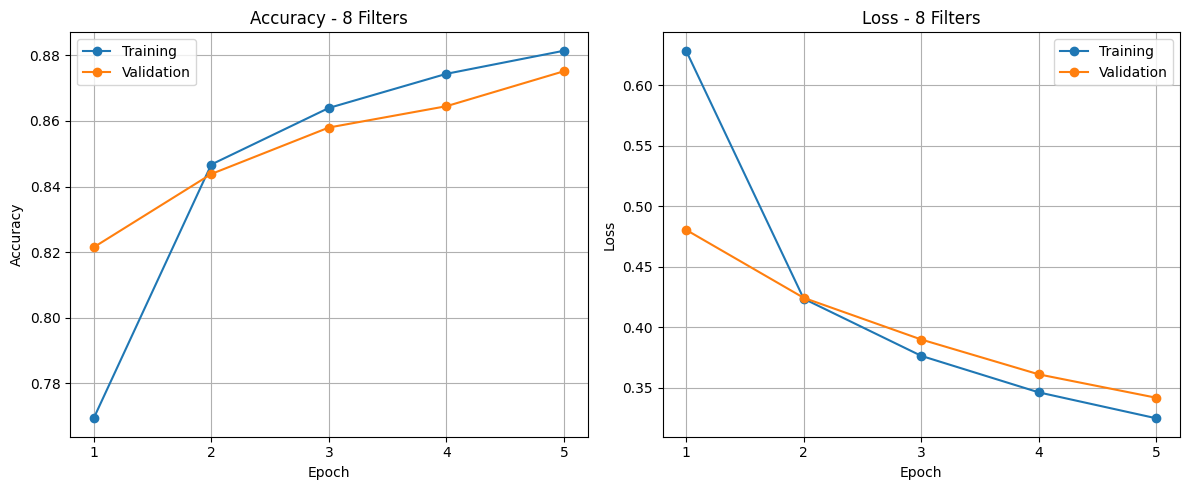

Grafik kaydedildi: deney_8_grafikler.png


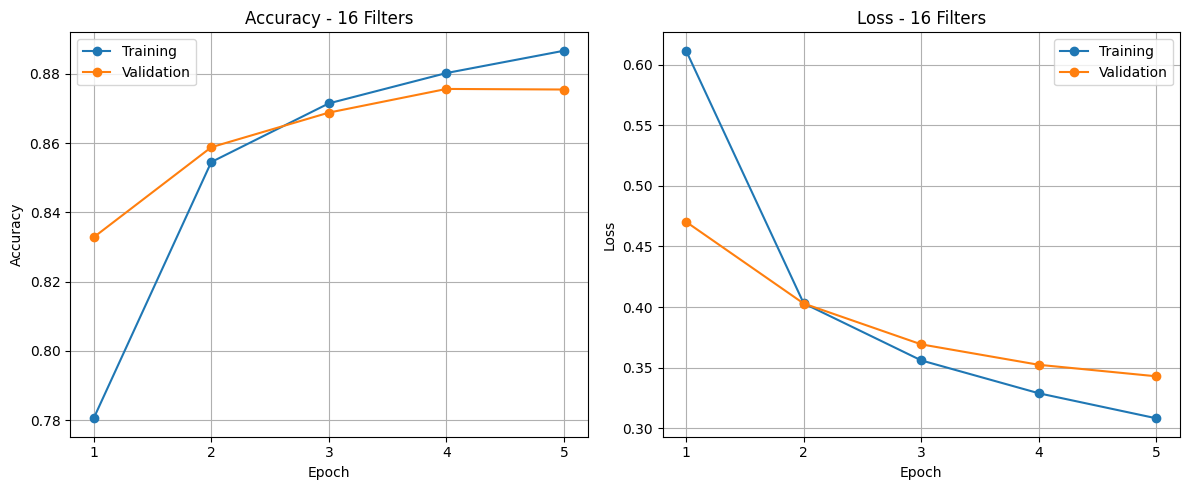

Grafik kaydedildi: deney_16_grafikler.png


In [ ]:

import matplotlib.pyplot as plt

def egitim_grafikleri(history, filtre_sayisi):

    epochs = range(
        1,
        len(history.history["accuracy"]) + 1
    )

    plt.figure(figsize=(12, 5))

    # Accuracy grafiği
    plt.subplot(1, 2, 1)

    plt.plot(
        epochs,
        history.history["accuracy"],
        marker="o",
        label="Training"
    )

    plt.plot(
        epochs,
        history.history["val_accuracy"],
        marker="o",
        label="Validation"
    )

    plt.title(f"Accuracy - {filtre_sayisi} Filters")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.xticks(list(epochs))
    plt.legend()
    plt.grid(True)

    # Loss grafiği
    plt.subplot(1, 2, 2)

    plt.plot(
        epochs,
        history.history["loss"],
        marker="o",
        label="Training"
    )

    plt.plot(
        epochs,
        history.history["val_loss"],
        marker="o",
        label="Validation"
    )

    plt.title(f"Loss - {filtre_sayisi} Filters")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(list(epochs))
    plt.legend()
    plt.grid(True)

    plt.tight_layout()

    # PNG dosyasını kaydet
    dosya = f"deney_{filtre_sayisi}_grafikler.png"
    plt.savefig(dosya, dpi=300, bbox_inches="tight")

    plt.show()

    print("Grafik kaydedildi:", dosya)


# Deney 1
egitim_grafikleri(history, 8)

# Deney 2
egitim_grafikleri(history_16, 16)


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Rastgelelik kontrolü
tf.keras.utils.set_random_seed(42)

# 16 filtreli konvolüsyon katmanı
conv = tf.keras.layers.Conv2D(
    filters=16,
    kernel_size=(3, 3),
    activation="relu",
    kernel_initializer="he_normal"
)

# 128x128 boyutlu örnek görüntü
dummy_input = tf.random.normal((1, 128, 128, 1))

# Konvolüsyon işlemini gerçekleştir
output = conv(dummy_input)

# Filtre ağırlıkları ve bias değerleri
weights, biases = conv.get_weights()

print("Giriş boyutu:", dummy_input.shape)
print("Çıkış boyutu:", output.shape)
print("Ağırlık boyutu:", weights.shape)
print("Bias boyutu:", biases.shape)


Giriş boyutu: (1, 128, 128, 1)
Çıkış boyutu: (1, 126, 126, 16)
Ağırlık boyutu: (3, 3, 1, 16)
Bias boyutu: (16,)


In [ ]:

# İlk filtrenin 3x3 ağırlık matrisi
first_filter = weights[:, :, 0, 0]

print("İlk filtrenin ağırlıkları:")
print(first_filter)

print("\nFiltrenin boyutu:", first_filter.shape)


İlk filtrenin ağırlıkları:
[[-0.25283593  0.12861036 -0.75786656]
 [-0.21681367 -0.15182823 -0.702172  ]
 [ 0.23038778  0.76512676 -0.74278826]]

Filtrenin boyutu: (3, 3)


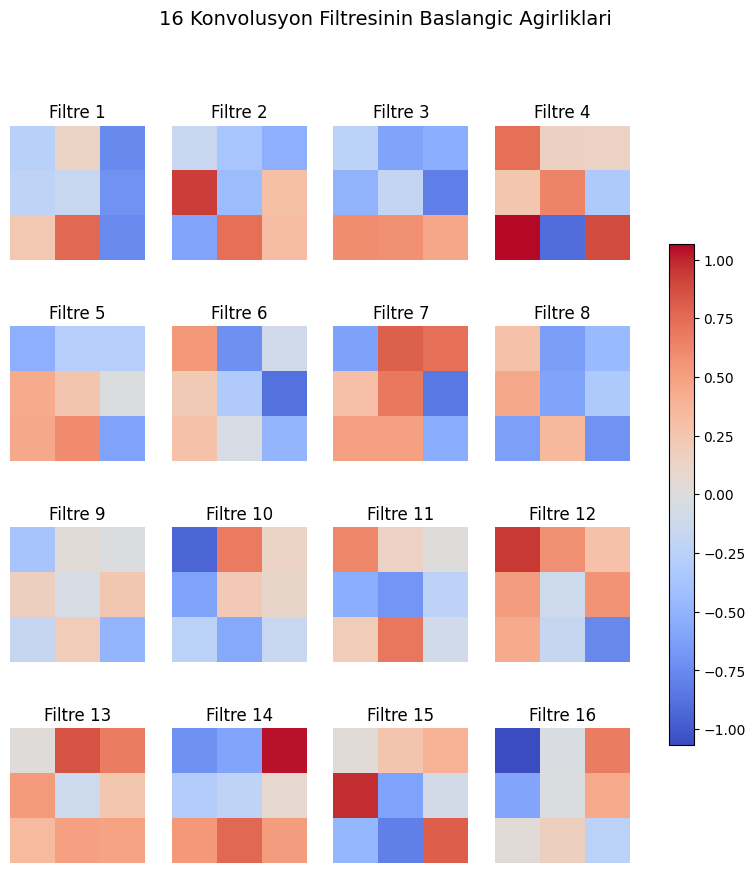

In [ ]:

# 4 satır ve 4 sütundan oluşan görsel alanı
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

# Bütün filtrelerde aynı renk ölçeğini kullan
limit = np.max(np.abs(weights))

# 16 filtrenin tamamını çiz
for i in range(16):

    # i. filtrenin ağırlıklarını al
    filter_weights = weights[:, :, 0, i]

    # İlgili grafik alanını seç
    ax = axes.flat[i]

    # Filtreyi görselleştir
    image = ax.imshow(
        filter_weights,
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit,
        interpolation="nearest"
    )

    ax.set_title(f"Filtre {i+1}")
    ax.axis("off")

# Renk ölçeği
fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    shrink=0.65
)

fig.suptitle(
    "16 Konvolusyon Filtresinin Baslangic Agirliklari",
    fontsize=14
)

# Görseli PNG olarak kaydet
plt.savefig(
    "konvolusyon_16_filtre.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# He Normal teorik hesaplama
fan_in = 3 * 3 * 1

theoretical_variance = 2 / fan_in
theoretical_std = np.sqrt(theoretical_variance)

print("Fan-in:", fan_in)
print("Hedef varyans:", theoretical_variance)
print("Hedef standart sapma:", theoretical_std)

print("\nGerçek başlangıç ağırlıkları:")
print("Ortalama:", np.mean(weights))
print("Örnek varyans:", np.var(weights))
print("Örnek standart sapma:", np.std(weights))
print("Minimum:", np.min(weights))
print("Maksimum:", np.max(weights))


Fan-in: 9
Hedef varyans: 0.2222222222222222
Hedef standart sapma: 0.4714045207910317

Gerçek başlangıç ağırlıkları:
Ortalama: 0.017164346
Örnek varyans: 0.26965654
Örnek standart sapma: 0.51928467
Minimum: -1.0662746
Maksimum: 1.0508786


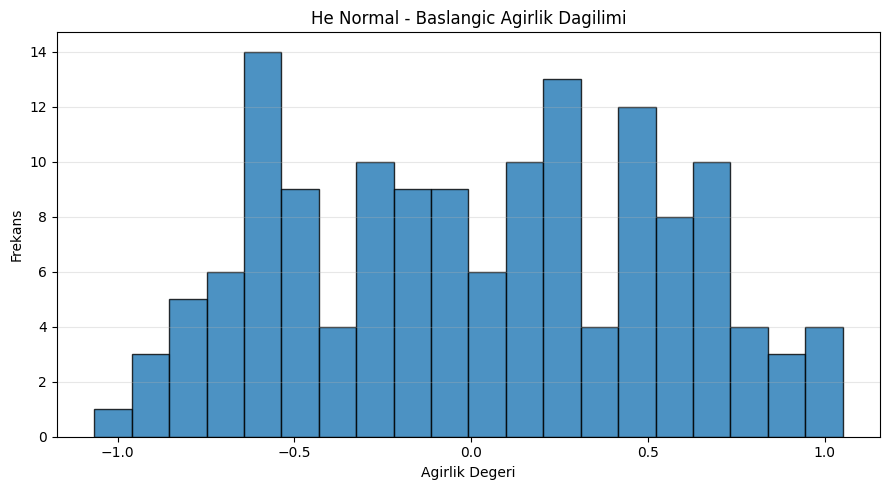

In [ ]:

plt.figure(figsize=(9, 5))

plt.hist(
    weights.flatten(),
    bins=20,
    edgecolor="black",
    alpha=0.8
)

plt.title("He Normal - Baslangic Agirlik Dagilimi")
plt.xlabel("Agirlik Degeri")
plt.ylabel("Frekans")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "filtre_agirlik_dagilimi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

total_weights = weights.size
total_biases = biases.size

total_parameters = total_weights + total_biases

print("Kernel ağırlıkları:", total_weights)
print("Bias parametreleri:", total_biases)
print("Toplam öğrenilebilir parametre:", total_parameters)


Kernel ağırlıkları: 144
Bias parametreleri: 16
Toplam öğrenilebilir parametre: 160


In [ ]:

import tensorflow as tf

# Hocanın verdiği 4x4 matris
input_data = tf.constant([
    [[1., 3., 2., 4.],
     [5., 6., 1., 2.],
     [7., 2., 8., 3.],
     [4., 1., 5., 9.]]
])

# TensorFlow'un beklediği 4 boyutlu yapıya dönüştür
input_data = tf.reshape(input_data, (1, 4, 4, 1))

# 2x2 Max Pooling katmanını oluştur
pool = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=2
)

# Pooling işlemini gerçekleştir
pool_output = pool(input_data)

print("Giriş matrisi:")
print(input_data.numpy()[0, :, :, 0])

print("\nPooling sonucu:")
print(pool_output.numpy()[0, :, :, 0])

print("\nGiriş boyutu:", input_data.shape)
print("Çıkış boyutu:", pool_output.shape)


Giriş matrisi:
[[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [4. 1. 5. 9.]]

Pooling sonucu:
[[6. 4.]
 [7. 9.]]

Giriş boyutu: (1, 4, 4, 1)
Çıkış boyutu: (1, 2, 2, 1)


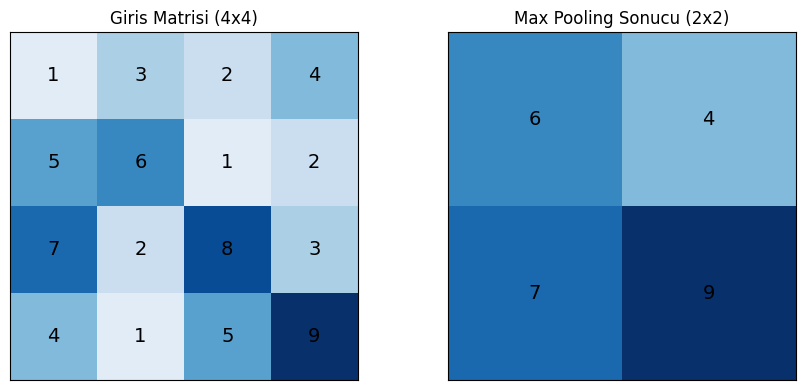

In [ ]:

import matplotlib.pyplot as plt

giris = input_data.numpy()[0, :, :, 0]
cikis = pool_output.numpy()[0, :, :, 0]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, matris, baslik in zip(
    axes,
    [giris, cikis],
    ["Giris Matrisi (4x4)", "Max Pooling Sonucu (2x2)"]
):
    ax.imshow(matris, cmap="Blues", vmin=0, vmax=9)

    for i in range(matris.shape[0]):
        for j in range(matris.shape[1]):
            ax.text(
                j, i, str(int(matris[i, j])),
                ha="center",
                va="center",
                fontsize=14
            )

    ax.set_title(baslik)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()

plt.savefig(
    "max_pooling_giris_cikis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

import tensorflow as tf

# Giriş değerleri
x = tf.constant([-5., -2., -1., 0., 2., 4., 6.])

# ReLU katmanı oluştur
relu = tf.keras.layers.ReLU()

# ReLU işlemini uygula
y = relu(x)

print("Giriş:", x.numpy())
print("ReLU çıkışı:", y.numpy())


Giriş: [-5. -2. -1.  0.  2.  4.  6.]
ReLU çıkışı: [0. 0. 0. 0. 2. 4. 6.]


In [ ]:

import tensorflow as tf

# Ham sınıf skorları
logits = tf.constant([[2.0, 1.0, 0.1]])

# Softmax katmanını oluştur
softmax = tf.keras.layers.Softmax()

# Skorları olasılığa dönüştür
probabilities = softmax(logits)

print("Softmax sonuçları:")
print(probabilities.numpy())

print("\nOlasılıkların toplamı:")
print(tf.reduce_sum(probabilities).numpy())

# En yüksek olasılığa sahip sınıf
predicted_class = tf.argmax(probabilities, axis=1)

print("\nTahmin edilen sınıf indeksi:")
print(predicted_class.numpy())


Softmax sonuçları:
[[0.6590012  0.24243298 0.09856589]]

Olasılıkların toplamı:
1.0000001

Tahmin edilen sınıf indeksi:
[0]
